# 04 · Failure Analysis
**Time: 20–30 minutes.**

## Learning Objectives
Locate the first observable error, connect a video frame to logged state, and separate facts from hypotheses.

## Background
A failed rollout can arise during approach, grasp, lift, transport, release or stabilization. A video alone rarely establishes the cause. Use the state and action traces to support your interpretation. Gripper opening (meters) and normalized gripper command (unitless) use different axes.

## Step-by-step Instructions
### Step 1 — Select a real failure
Use the primary student model. If it has no completed failure, use an explicitly attributed instructor reference failure. The fallback never changes student evaluation scores. Missing reference evidence produces a clear message; no artificial failure is generated.


> **Executed instructor solution — 2026-10-13.** Original student templates are preserved. Computation and answer-edit sessions are recorded in solution_execution.json. These answers interpret this particular run. Training and policy evaluation were each performed once in the completed run.

In [1]:
from pathlib import Path
import os, json
from IPython.display import display, Markdown, Image, Video
from manipulation_lab.common import ROOT, DATA, write_json
from manipulation_lab.notebook import workspace, command, next_stage, stage_path
from manipulation_lab.teaching import read_json, markdown_table
GROUP = os.environ.get("LAB_GROUP", "group_01")  # Use the group assigned by your instructor.
RUN = workspace(GROUP)
EXPERIMENT = stage_path(RUN, "experiment")
experiment = read_json(EXPERIMENT / "experiment.json")
assert experiment["complete"], "Complete both learning-rate runs in Notebook 02 first."
primary = experiment["variants"][experiment["primary_variant"]]
TRAINING = EXPERIMENT / primary["training"]
EVALUATION = EXPERIMENT / primary["evaluation"]


group_01 → /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c


In [2]:
FAILURE_EVALUATION = EVALUATION
results = read_json(FAILURE_EVALUATION / "summary.json")
failures = [r for r in results["episodes"] if not r["stable_success"] and not r["error"] and r["video"]]
if not failures:
    reference = Path(os.environ.get("LAB_REFERENCE_ROOT", ROOT / "checkpoints"))
    FAILURE_EVALUATION = reference / "reference_evaluation"
    if not (FAILURE_EVALUATION / "summary.json").is_file():
        raise FileNotFoundError("No primary-policy failure and no instructor reference. Ask the instructor to run prepare_reference.py --train and set LAB_REFERENCE_ROOT; see docs/server_setup.md.")
    results = read_json(FAILURE_EVALUATION / "summary.json")
    assert results["policy_role"] == "instructor_reference"
    failures = [r for r in results["episodes"] if not r["stable_success"] and not r["error"] and r["video"]]
    if not failures:
        raise RuntimeError("No completed real failure is available. Instructor must supply attributed evidence; do not invent a case.")
    print("Evidence source: instructor reference. Student scores are unchanged.")
display(Markdown(markdown_table(failures, ["episode_id", "source_episode", "steps", "environment_success", "stable_success"])))
EPISODE = 'standard_00'  # You may choose another failure from this table.
selected = next(r for r in failures if r["episode_id"] == EPISODE)
print("Selected:", EPISODE, "Available control steps: 0..", selected["steps"])


| episode_id | source_episode | steps | environment_success | stable_success |
| --- | --- | --- | --- | --- |
| standard_00 | demo_39 | 500 | False | False |
| standard_03 | demo_48 | 500 | False | False |
| shifted_00 | demo_39 | 500 | False | False |
| shifted_03 | demo_48 | 500 | False | False |

Selected: standard_00 Available control steps: 0.. 500


### Step 2 — Choose control steps and mark the first observable error
Watch the full video, then change `KEYFRAME_STEPS`. Set `FIRST_ERROR_STEP` to the first step where you can support an error from evidence; leave `None` while undecided.

State 0 precedes the first action. Action `a[t-1]` leads to state `s[t]`. Video is sampled every four steps **after** an action, so a requested state may have no exact video frame. The nearest actual frame is shown with its offset; no missing frames are synthesized. State values below belong to the **requested control step**, not to an offset frame. Rerun Steps 2–4 to save a new analysis version.


In [3]:
display(Video(str(FAILURE_EVALUATION / selected["video"]), embed=True))
KEYFRAME_STEPS = [45, 53, 57, 65]
FIRST_ERROR_STEP = 57

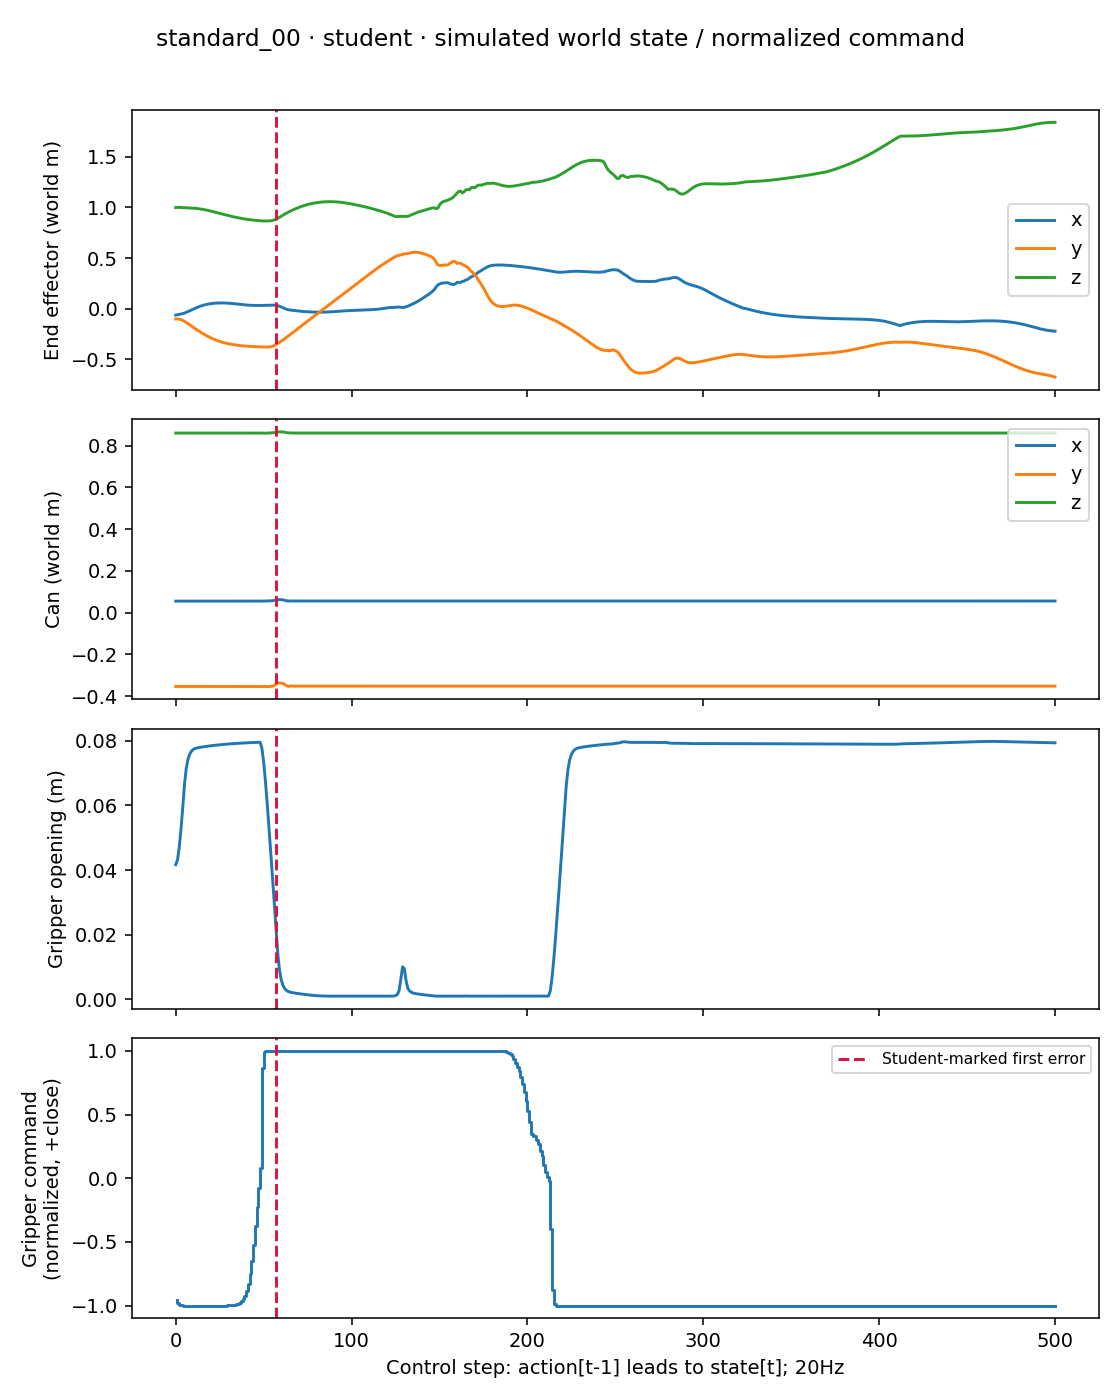

Requested step: 45 Recorded step: 45 Offset: 0 Video frame: 11


| control_step | control_elapsed_s | eef_world_position_m | object_world_position_m | gripper_opening_m | preceding_normalized_action |
| --- | --- | --- | --- | --- | --- |
| 45 | 2.25 | [0.031062736112389706, -0.37649858028974154, 0.8735973152319986] | [0.0545723184101044, -0.3542418919882997, 0.8600593447836751] | 0.07948372276030652 | [0.013037006370723248, -0.04854558780789375, -0.11497293412685394, 0.01707308739423752, -0.005030746106058359, 0.009607089683413506, -0.5209231376647949] |

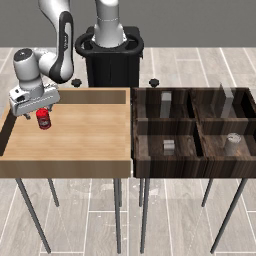

Requested step: 53 Recorded step: 53 Offset: 0 Video frame: 13


| control_step | control_elapsed_s | eef_world_position_m | object_world_position_m | gripper_opening_m | preceding_normalized_action |
| --- | --- | --- | --- | --- | --- |
| 53 | 2.65 | [0.03331231425667881, -0.37946810802320546, 0.8673257331599752] | [0.0557954554580835, -0.3546104706657447, 0.8599363489996569] | 0.053412513634457856 | [0.08206679672002792, 0.11618322134017944, 0.07487431913614273, 0.03177338466048241, 0.00790945254266262, -0.006990558002144098, 0.9996772408485413] |

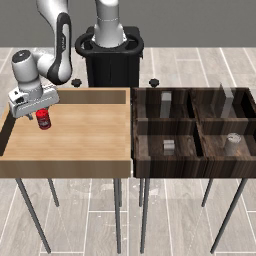

Requested step: 57 Recorded step: 57 Offset: 0 Video frame: 14


| control_step | control_elapsed_s | eef_world_position_m | object_world_position_m | gripper_opening_m | preceding_normalized_action |
| --- | --- | --- | --- | --- | --- |
| 57 | 2.85 | [0.03311728428801661, -0.35641222474432505, 0.883758602529041] | [0.06005451982476621, -0.34271925474054715, 0.8646673125759224] | 0.022397882728517934 | [-0.1582263857126236, 0.9963191747665405, 0.6318642497062683, 0.06401056051254272, 0.027188487350940704, -0.19084890186786652, 1.0] |

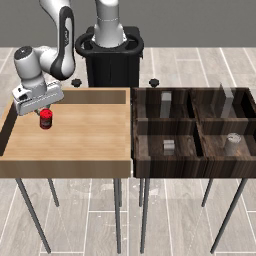

Requested step: 65 Recorded step: 65 Offset: 0 Video frame: 16


| control_step | control_elapsed_s | eef_world_position_m | object_world_position_m | gripper_opening_m | preceding_normalized_action |
| --- | --- | --- | --- | --- | --- |
| 65 | 3.25 | [-0.013942392718176804, -0.2575838990414022, 0.9627110031583774] | [0.055488224328102034, -0.3521021868921496, 0.8602713911906941] | 0.0022418952319060554 | [0.004432213492691517, 0.9999960660934448, 0.6794843077659607, 0.12316856533288956, 0.08038754016160965, -0.3765619099140167, 1.0] |

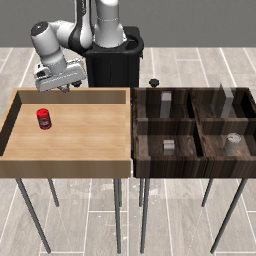

In [4]:
from manipulation_lab.reporting import failure_evidence
ANALYSIS = next_stage(RUN, "analysis")
ANALYSIS.mkdir()
facts = failure_evidence(FAILURE_EVALUATION, EPISODE, ANALYSIS,
                         requested_steps=KEYFRAME_STEPS, first_error_step=FIRST_ERROR_STEP)
display(Image(filename=str(ANALYSIS / "failure_signals.png")))
for frame in facts["keyframes"]:
    print("Requested step:", frame["requested_control_step"], "Recorded step:", frame["recorded_control_step"],
          "Offset:", frame["offset_steps"], "Video frame:", frame["video_frame_index"])
    display(Markdown(markdown_table([frame["requested_state"]])))
    display(Image(filename=str(ANALYSIS / frame["file"])))


### Step 3 — Explain your evidence
**Q5. Identify one failure and propose a possible improvement.** Choose a stage (or `unknown`), describe the earliest visible error, propose a cause, and suggest a test of that cause. The red line is your annotation, not an automatically inferred cause.


In [5]:
FAILURE_STAGE = 'grasp retention / beginning of lift'
FIRST_OBSERVABLE_ERROR = 'In primary student lr_a, standard_00 (demo_39, seed 101), contact is true at states 49-56 and becomes false at state 57, remaining false to the end. I annotate state 57 as the first directly supported loss of grasp contact, not as a proven earliest causal deviation. At state 57 (2.85 s of control time), opening is 0.022398 m, end-effector Z is 0.883759 m, can Z is 0.864667 m, and preceding action a[56] commands closure approximately +1. At state 65, end-effector Z rises to 0.962711 m but can Z returns to 0.860271 m and opening shrinks to 0.002242 m: the hand rises without retaining the can. The maximum object lift over the rollout is only 0.005722 m; no target-margin or environment success occurs before the 500-step horizon. Inspected states 45, 53, 57 and 65 correspond exactly to recorded video frames 11, 13, 14 and 16, with zero offset. In general a[t-1] leads to s[t], and video samples states 1,5,9,... after actions, so nearby frames must not be treated as exact requested states.'
HYPOTHESIZED_CAUSE = 'The approach pose may not center the can securely between the fingers, or closure and upward motion may be poorly timed. A positive closure command and brief contact do not guarantee force closure or persistent retention. Logged contact loss and the video support failed retention, but do not distinguish alignment, timing and contact dynamics. The single-view video does not identify the earliest causal error or prove covariate shift; those remain hypotheses.'
IMPROVEMENT = 'Proposed, not executed: capture the complete simulator and controller state just before closure, including the same policy checkpoint and random state. Compare an unchanged continuation with one predefined intervention that holds the pre-lift end-effector pose while closing for a fixed five control steps, then resumes the same policy. Change only that timing rule, keep the initial state, dynamics and success thresholds identical, and compare duration of contact, can height relative to its initial height, and eventual stable placement on the same cases. An improvement would support a closure-timing contribution; no improvement would leave alignment/contact hypotheses unresolved. This tests an intervention, not a claimed guaranteed fix. Any additional data or model modification should be a separate declared experiment.'
write_json(ANALYSIS / "failure_analysis.json", {
    "episode": EPISODE, "evidence_directory": os.path.relpath(FAILURE_EVALUATION, ANALYSIS),
    "evidence_policy_role": results["policy_role"], "evidence_checkpoint_sha256": results["checkpoint_sha256"],
    "stage": FAILURE_STAGE, "first_observable_error": FIRST_OBSERVABLE_ERROR,
    "first_error_control_step": FIRST_ERROR_STEP,
    "hypothesized_cause": HYPOTHESIZED_CAUSE, "improvement": IMPROVEMENT})
display(Markdown("**Q5 — Instructor solution**\n\n" + FIRST_OBSERVABLE_ERROR + "\n\n**Hypothesis:** " + HYPOTHESIZED_CAUSE + "\n\n**Proposed test:** " + IMPROVEMENT))

**Q5 — Instructor solution**

In primary student lr_a, standard_00 (demo_39, seed 101), contact is true at states 49-56 and becomes false at state 57, remaining false to the end. I annotate state 57 as the first directly supported loss of grasp contact, not as a proven earliest causal deviation. At state 57 (2.85 s of control time), opening is 0.022398 m, end-effector Z is 0.883759 m, can Z is 0.864667 m, and preceding action a[56] commands closure approximately +1. At state 65, end-effector Z rises to 0.962711 m but can Z returns to 0.860271 m and opening shrinks to 0.002242 m: the hand rises without retaining the can. The maximum object lift over the rollout is only 0.005722 m; no target-margin or environment success occurs before the 500-step horizon. Inspected states 45, 53, 57 and 65 correspond exactly to recorded video frames 11, 13, 14 and 16, with zero offset. In general a[t-1] leads to s[t], and video samples states 1,5,9,... after actions, so nearby frames must not be treated as exact requested states.

**Hypothesis:** The approach pose may not center the can securely between the fingers, or closure and upward motion may be poorly timed. A positive closure command and brief contact do not guarantee force closure or persistent retention. Logged contact loss and the video support failed retention, but do not distinguish alignment, timing and contact dynamics. The single-view video does not identify the earliest causal error or prove covariate shift; those remain hypotheses.

**Proposed test:** Proposed, not executed: capture the complete simulator and controller state just before closure, including the same policy checkpoint and random state. Compare an unchanged continuation with one predefined intervention that holds the pre-lift end-effector pose while closing for a fixed five control steps, then resumes the same policy. Change only that timing rule, keep the initial state, dynamics and success thresholds identical, and compare duration of contact, can height relative to its initial height, and eventual stable placement on the same cases. An improvement would support a closure-timing contribution; no improvement would leave alignment/contact hypotheses unresolved. This tests an intervention, not a claimed guaranteed fix. Any additional data or model modification should be a separate declared experiment.

### Step 4 — Generate the report and evidence archive
Complete Q1 in Notebook 01, Q2–Q3 in Notebook 02 and Q4 in Notebook 03 by rerunning their **answer cells only**, then regenerate this report. Blank answers or an unmarked error keep it in **DRAFT** status. The generated Markdown is an evidence appendix; write a concise **1–2 page report** using the [assignment guide](../docs/assignment_student.md).


Running generate_report.py


/home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c/report_052630_5b255a/report.md


# Manipulation Learning Lab — Group Report

Status: student answers provided; instructor review required

Run: `20261013T051828Z_5a8ae81c`. Policy: **student_deterministic_mlp** (student).
Training: 50 epochs, selected epoch 12, validation action MSE 0.03538; 9.6s.

| Condition | Episodes | Environment success | Stable released placement |
|---|---:|---:|---:|
| standard | 5 | 60% | 60% |
| shifted | 5 | 60% | 60% |

Five episodes give a coarse classroom estimate. Position Shift Test is not a certified OOD benchmark.

## Demonstration understanding

Q1: The policy observes 16 values: end-effector world position (3), end-effector xyzw quaternion (4), two finger joint positions (2), and can world position plus xyzw quaternion (7). Positions and finger joint displacements are in meters, with world Z upward; quaternion components are dimensionless. The adapter takes object[7:14] from the raw 14-value object vector in both training and inference. The seven normalized actions are world translation increments (3), axis-angle rotation increments (3), and one gripper command (1). Commands lie in [-1,1]; translation and rotation scale to controller limits of +/-0.05 m and +/-0.5 rad. A positive gripper command closes and a negative command opens; it is not a measured opening in meters. Two finger joints give two observation values but only one independent open/close command. The control frequency is 20 Hz, so one interval is 0.05 s; step indices are not acquisition timestamps.

Demonstration reflection: demo_0 contains 118 recorded steps. Its first positive gripper command is action index 52; the can height ranges from 0.85851 to 1.01071 m over the recorded observations. A final image cannot reveal approach, closure, lift, transport and release ordering or provide the aligned observation/expert-action pairs needed for training. The trajectory does. A commanded closure alone does not prove secure grasping. Demonstration playback restores recorded simulator states and is distinct from a learned-policy rollout. The 160/20/20 split keeps complete episodes together, reducing leakage of adjacent correlated states; only the 160 training episodes supply normalization statistics.

## Training and evaluation discussion

Q2 — How BC learns: Behavior cloning is supervised learning of a policy pi_theta(o) that maps the current 16-value observation to the seven recorded expert action labels. The fixed deterministic MLP has three 256-unit hidden layers. It minimizes mean squared action error, averaged over examples and action coordinates; gradient-based updates change the network weights. An epoch traverses the training examples. Observation normalization uses training data only. Validation loss is measured without fitting validation labels and selects the saved checkpoint; both variants selected epoch 12 out of 50. The test episodes never update weights or select the primary model. The mandatory experiment changes only learning rate (0.001 vs 0.0003), keeping seed 17, batch size 256, data, episode split, initialization, network, normalization, training device and evaluation cases fixed. All four control checks passed. lr_a was declared primary before testing.

Q3 — Loss versus performance: No. In this actual CPU run, epoch-50 training MSE is 0.01771696 for lr_a and 0.02091872 for lr_b, so lr_a fits training examples more closely. Their best validation MSE values are 0.03537583 and 0.03412256, both at epoch 12. Using those validation-selected checkpoints, lr_a achieves stable released placement in 3/5 standard and 3/5 shifted cases, while lr_b achieves 5/5 and 5/5. Environment-success counts happen to match stable-placement counts here, but the definitions differ. The evaluated weights are epoch-12 checkpoints, not the epoch-50 weights: this comparison warns against ranking policies by final training loss; it is not a causal test of loss at fixed weights. During closed-loop execution, each action changes subsequent observations, so errors can move the policy into states less well represented in demonstrations. Five cases per condition are coarse (one case equals 20 percentage points), and this one training seed cannot establish a generally superior learning rate. No unsuccessful cases were discarded or rerun to improve scores.

Q4 — Initial position: The shift adds +0.04 m to the initial can world X while retaining the same held-out source episode and seed, with the shifted position constrained to the source bin. All paired success/failure labels are unchanged in this run: lr_a succeeds on demo_185, demo_29 and demo_157 and fails on demo_39 and demo_48 under both conditions; lr_b succeeds on all five under both. However, behavior is not identical. For lr_a on demo_185, seed 102, stable completion takes 141 standard steps versus 156 shifted steps, a 15-step (0.75 s) increase. For lr_b on demo_48, completion instead changes from 182 to 141 steps. A possible explanation is different approach/grasp geometry, but the timing difference alone cannot prove that mechanism. In the coverage plot, grey dots are 160 training initial positions, colored markers are actual evaluated starts, and lines connect paired starts: none is a trajectory or a success marker. Shifted starts can overlap the training-position range, and world XY alone omits the other observation dimensions. Thus this is a position sensitivity test, not certified out-of-distribution generalization.

Q5 is addressed by the failure analysis below.

## Failure analysis

Episode: standard_00; evidence policy role: student.

**Failure stage:** grasp retention / beginning of lift

**First observable error — fact:** In primary student lr_a, standard_00 (demo_39, seed 101), contact is true at states 49-56 and becomes false at state 57, remaining false to the end. I annotate state 57 as the first directly supported loss of grasp contact, not as a proven earliest causal deviation. At state 57 (2.85 s of control time), opening is 0.022398 m, end-effector Z is 0.883759 m, can Z is 0.864667 m, and preceding action a[56] commands closure approximately +1. At state 65, end-effector Z rises to 0.962711 m but can Z returns to 0.860271 m and opening shrinks to 0.002242 m: the hand rises without retaining the can. The maximum object lift over the rollout is only 0.005722 m; no target-margin or environment success occurs before the 500-step horizon. Inspected states 45, 53, 57 and 65 correspond exactly to recorded video frames 11, 13, 14 and 16, with zero offset. In general a[t-1] leads to s[t], and video samples states 1,5,9,... after actions, so nearby frames must not be treated as exact requested states.

**Possible cause — hypothesis:** The approach pose may not center the can securely between the fingers, or closure and upward motion may be poorly timed. A positive closure command and brief contact do not guarantee force closure or persistent retention. Logged contact loss and the video support failed retention, but do not distinguish alignment, timing and contact dynamics. The single-view video does not identify the earliest causal error or prove covariate shift; those remain hypotheses.

**Proposed improvement:** Proposed, not executed: capture the complete simulator and controller state just before closure, including the same policy checkpoint and random state. Compare an unchanged continuation with one predefined intervention that holds the pre-lift end-effector pose while closing for a fixed five control steps, then resumes the same policy. Change only that timing rule, keep the initial state, dynamics and success thresholds identical, and compare duration of contact, can height relative to its initial height, and eventual stable placement on the same cases. An improvement would support a closure-timing contribution; no improvement would leave alignment/contact hypotheses unresolved. This tests an intervention, not a claimed guaranteed fix. Any additional data or model modification should be a separate declared experiment.

**First error control step (student annotation):** 57

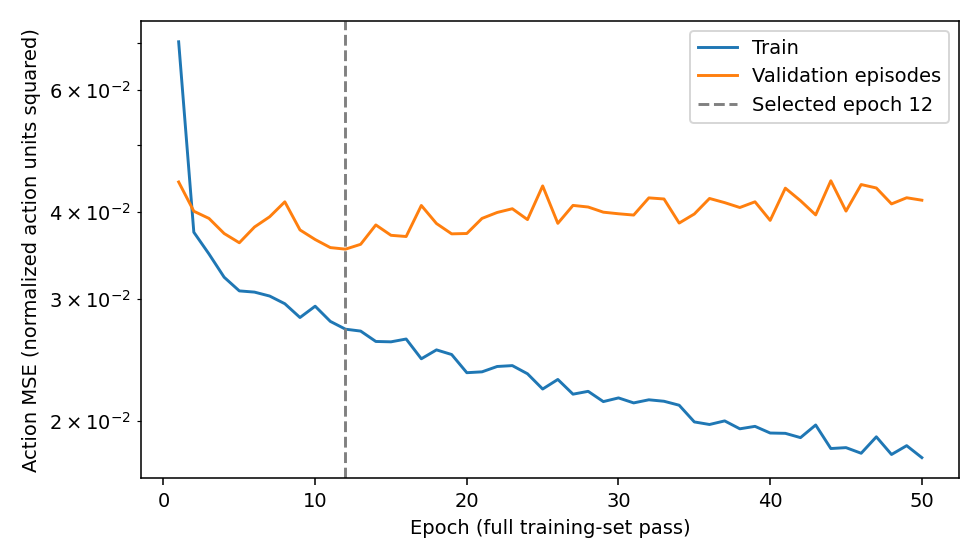

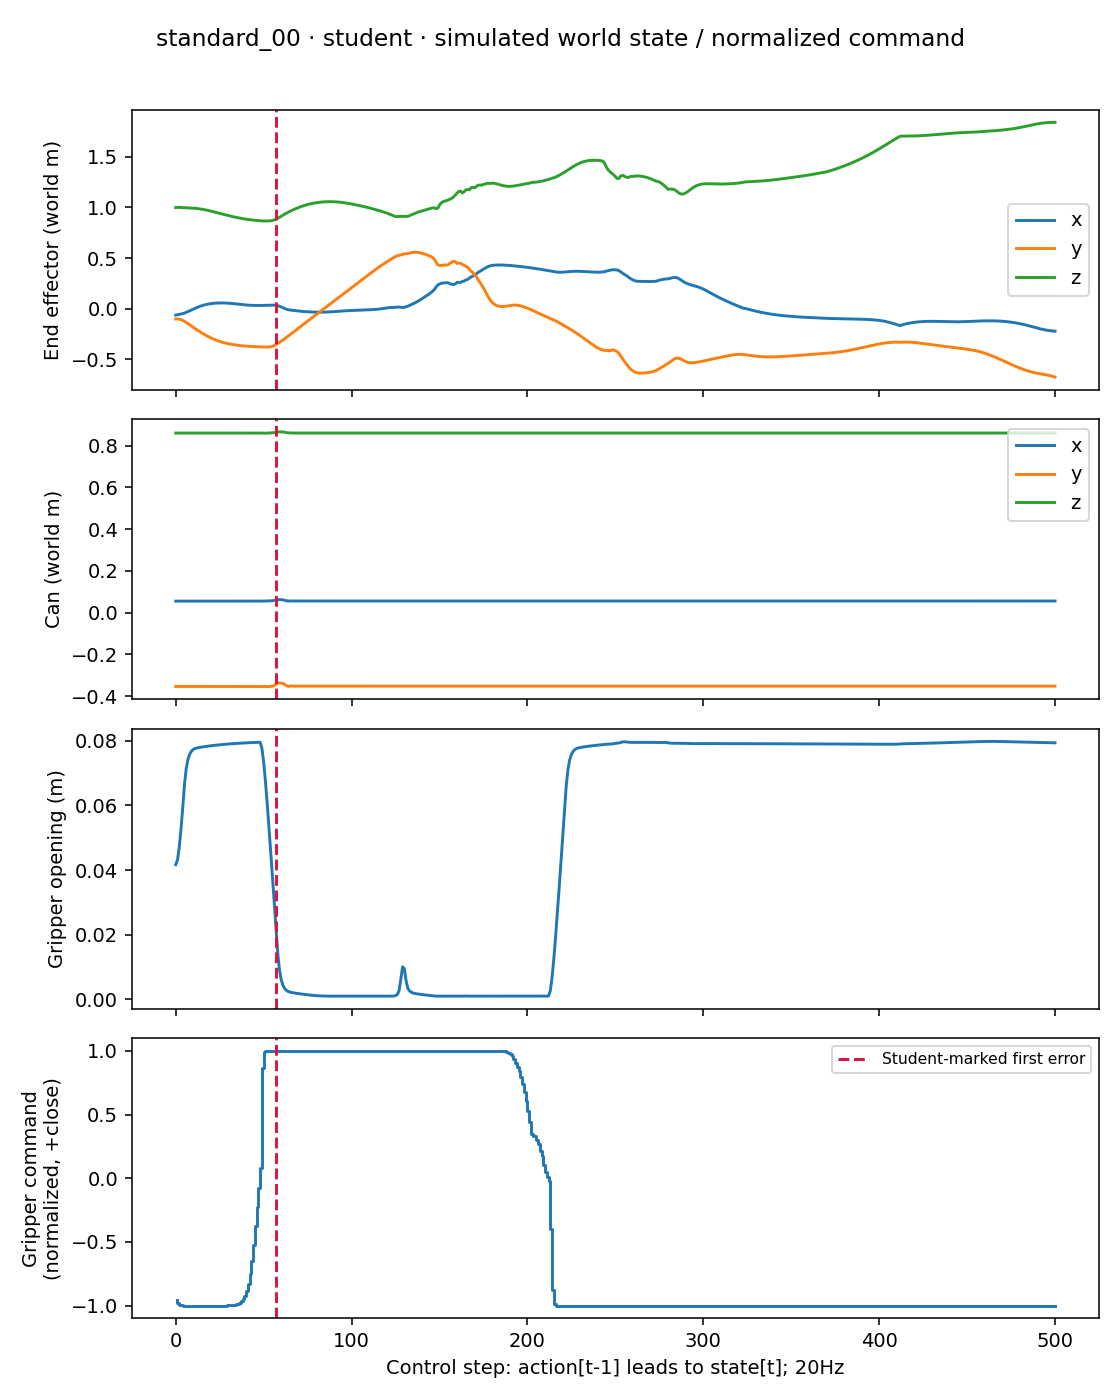

## Evidence and limits

Checkpoint SHA256: `e9771831a6563677cd6db4585b630b54c6f1e14668e4443e1a71e705290c7033`.
Positions are simulator world coordinates in meters; logs use 20Hz control steps. No real-robot claim is made.
Attach training_config.json, training_log.csv, evaluation results/config/manifest, and 3 keyframes. Keep raw artifacts separately.

Requested control step 45; recorded step 45 (offset +0); video frame 11.
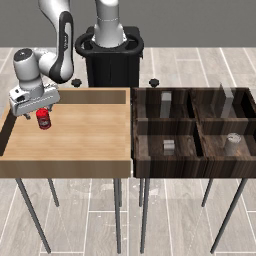

Requested control step 53; recorded step 53 (offset +0); video frame 13.
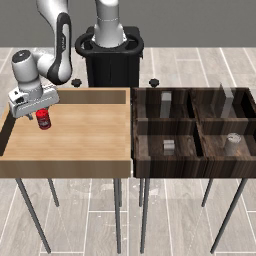

Requested control step 57; recorded step 57 (offset +0); video frame 14.
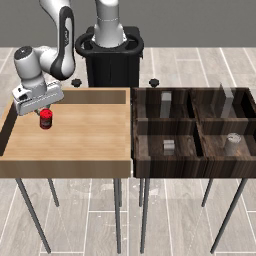

Requested control step 65; recorded step 65 (offset +0); video frame 16.
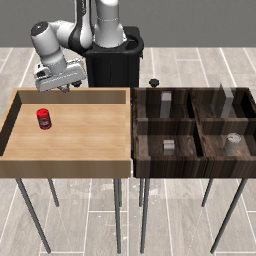

## Mandatory learning-rate controlled experiment

Data, initialization, seed, architecture, epochs and evaluation cases are fixed. Both variants are retained; test results do not select the primary model.

| Variant | Learning rate | Validation MSE | Standard stable | Shifted stable |
|---|---:|---:|---:|---:|
| lr_a | 0.001 | 0.035376 | 60% | 60% |
| lr_b | 0.0003 | 0.034123 | 100% | 100% |

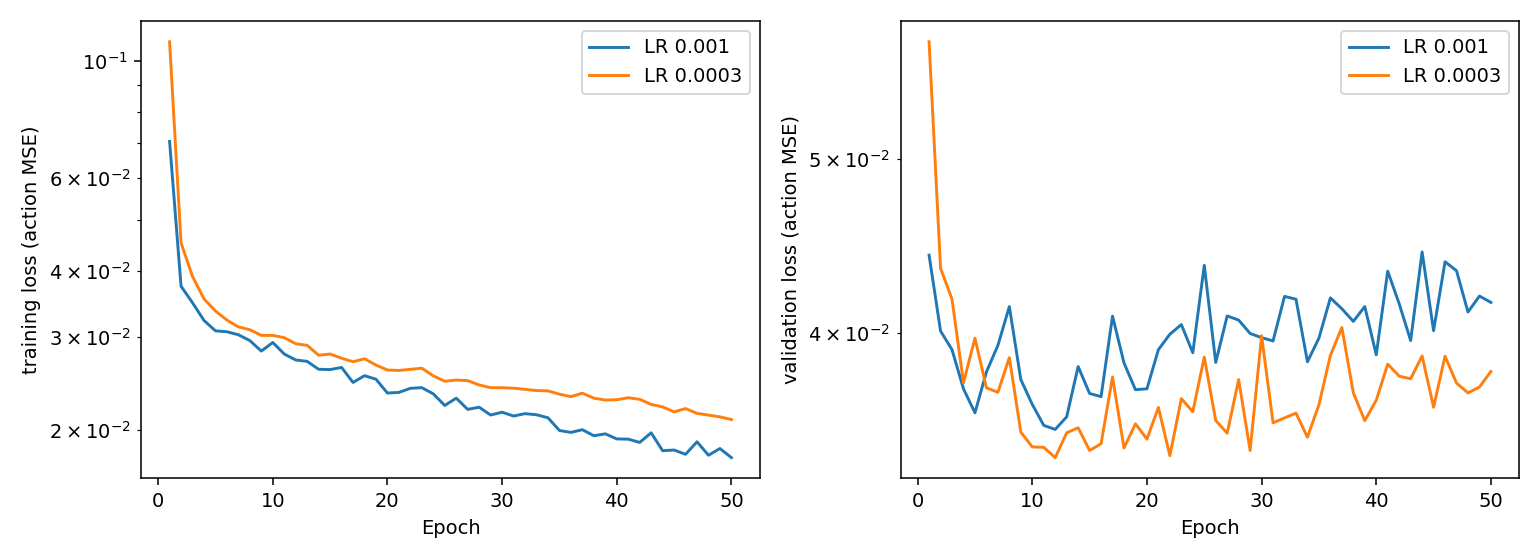

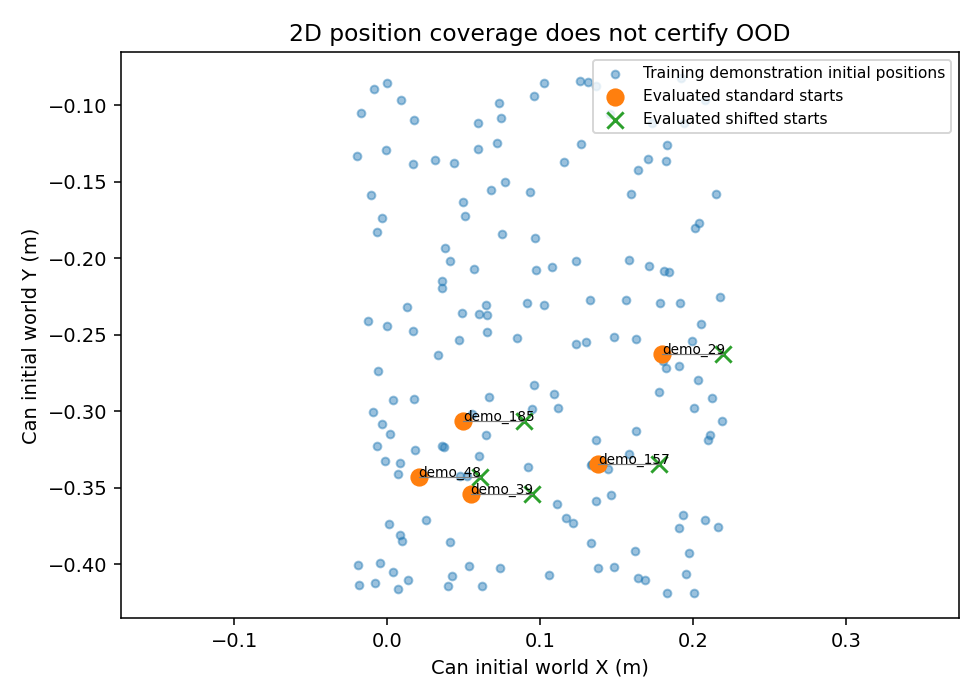


Running export_submission.py


Saved /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c_report_052630_5b255a_submission.zip; answers_complete=True. Add your 1–2 page report before submission.
Evidence archive: /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c_report_052630_5b255a_submission.zip
Add your own 1–2 page PDF report. Use your IDE file explorer to download the ZIP when working remotely.


In [6]:
REPORT = next_stage(RUN, "report")
command("generate_report.py", "--run", RUN, "--output", REPORT)
from manipulation_lab.reporting import notebook_report_markdown
display(Markdown(notebook_report_markdown(REPORT / "report.md")))
ARCHIVE = RUN.parent / (RUN.name + "_" + REPORT.name + "_submission.zip")
command("export_submission.py", "--run", RUN, "--output", ARCHIVE)
print("Evidence archive:", ARCHIVE)
print("Add your own 1–2 page PDF report. Use your IDE file explorer to download the ZIP when working remotely.")


## Expected Outputs
A real failed-rollout video, four separate signal axes, selected keyframes with exact requested-state values, a saved first-error annotation, a report draft/completed-answer status, and an evidence ZIP. The ZIP includes both configurations, checkpoints, curves, evaluation records, videos and class CSV rows.

## Questions for Students
Does the visible error prove your proposed cause? What additional controlled test would distinguish that cause from an alternative explanation? Include this limitation in Q5.

## Completion Checklist
- [x] I selected real, attributed failure evidence and inspected at least three steps.
- [x] I marked the first observable error and separated fact from hypothesis.
- [x] I answered Q1–Q5 and regenerated the report after saving answers.
- [x] I prepared a 1–2 page report and the evidence ZIP with both variants.
- [x] I retained original outcomes and did not rerun seeds to improve the score.

Grading: demonstration understanding 20, training/experiment 25, evaluation 30, failure analysis/discussion 25. Success rate itself is not a grade.
